# Experiment 7: Sentiment Analysis & Comparative Study
In this notebook, we will implement and compare four models for sentiment analysis on the IMDB Movie Reviews Dataset:
1. **Logistic Regression** (Baseline)
2. **LSTM** (Recurrent Neural Network)
3. **Vanilla Transformer** (Self-Attention Network)
4. **BERT** (Pre-trained Transformer Fine-tuning)

We will evaluate each model using **Precision, Recall, F1-Score, and Confusion Matrices**.

In [1]:
# 1. Mount Google Drive and Import Libraries
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, GlobalAveragePooling1D, LayerNormalization, MultiHeadAttention

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# 2. Load and Preprocess the Dataset
dataset_path = '/content/drive/MyDrive/Colab Notebooks/CL-NLP - Lab/lab-7/IMDB Dataset.csv'

# Check if file exists
if os.path.exists(dataset_path):
    df = pd.read_csv(dataset_path)
    print(f"Dataset loaded successfully. Shape: {df.shape}")
else:
    print(f"Error: Dataset not found at {dataset_path}. Please verify the path.")

# Map sentiments to binary values
df['sentiment'] = df['sentiment'].map({'positive': 1, 'negative': 0})

# Simple text cleaning function
def clean_text(text):
    text = text.lower()
    text = re.sub(r'<br\s*/?>', ' ', text) # Remove HTML tags
    text = re.sub(r'[^a-zA-Z\s]', '', text) # Keep only alphabetic chars
    text = re.sub(r'\s+', ' ', text).strip() # Remove extra spaces
    return text

df['clean_review'] = df['review'].apply(clean_text)
display(df.head())

Dataset loaded successfully. Shape: (50000, 2)


,review,sentiment,clean_review
0,One of the other reviewers has mentioned that ...,1,one of the other reviewers has mentioned that ...
1,A wonderful little production. <br /><br />The...,1,a wonderful little production the filming tech...
2,I thought this was a wonderful way to spend ti...,1,i thought this was a wonderful way to spend ti...
3,Basically there's a family where a little boy ...,0,basically theres a family where a little boy j...
4,"Petter Mattei's ""Love in the Time of Money"" is...",1,petter matteis love in the time of money is a ...


In [3]:
# 3. Split the Dataset and Initialize Performance Tracking
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    df['clean_review'], df['sentiment'], test_size=0.2, random_state=42, stratify=df['sentiment']
)

# Dict to store evaluation results for final comparison
metrics_dict = {}

def plot_confusion_matrix(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
    plt.title(f'Confusion Matrix - {model_name}')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()

def evaluate_model(y_true, y_pred, model_name):
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='binary')
    acc = accuracy_score(y_true, y_pred)
    metrics_dict[model_name] = {'Accuracy': acc, 'Precision': precision, 'Recall': recall, 'F1-Score': f1}
    print(f"--- {model_name} Performance ---")
    print(classification_report(y_true, y_pred, target_names=['Negative', 'Positive']))
    plot_confusion_matrix(y_true, y_pred, model_name)

## Model 1: Logistic Regression (TF-IDF Baseline)

--- Logistic Regression Performance ---
              precision    recall  f1-score   support

    Negative       0.90      0.89      0.90      5000
    Positive       0.89      0.90      0.90      5000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



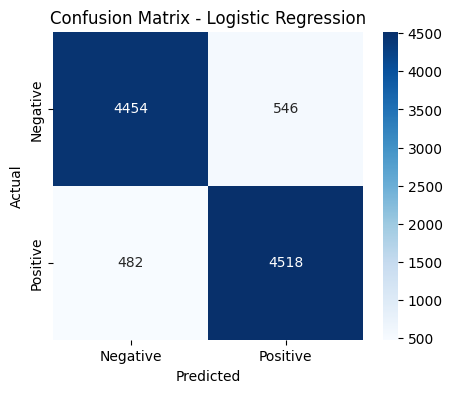

In [4]:
# Vectorize using TF-IDF
vectorizer = TfidfVectorizer(max_features=10000)
X_train_tfidf = vectorizer.fit_transform(X_train_raw)
X_test_tfidf = vectorizer.transform(X_test_raw)

# Train Logistic Regression
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)

# Predict and Evaluate
lr_preds = lr_model.predict(X_test_tfidf)
evaluate_model(y_test, lr_preds, "Logistic Regression")

## Model 2: LSTM (Deep Learning)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/3
282/282 ━━━━━━━━━━━━━━━━━━━━ 81s 275ms/step - accuracy: 0.5211 - loss: 0.6912 - val_accuracy: 0.5285 - val_loss: 0.6885
Epoch 2/3
282/282 ━━━━━━━━━━━━━━━━━━━━ 76s 270ms/step - accuracy: 0.5955 - loss: 0.6529 - val_accuracy: 0.5462 - val_loss: 0.6760
Epoch 3/3
282/282 ━━━━━━━━━━━━━━━━━━━━ 83s 275ms/step - accuracy: 0.6448 - loss: 0.6132 - val_accuracy: 0.6310 - val_loss: 0.6128
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step
--- LSTM Performance ---
              precision    recall  f1-score   support

    Negative       0.72      0.40      0.51      5000
    Positive       0.58      0.84      0.69      5000

    accuracy                           0.62     10000
   macro avg       0.65      0.62      0.60     10000
weighted avg       0.65      0.62      0.60     10000



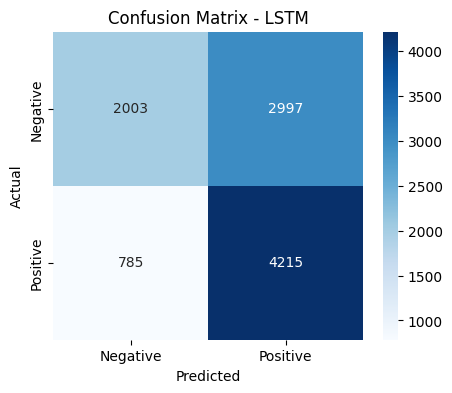

In [5]:
# Tokenization and Sequence Padding
max_words = 20000
max_len = 200

tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train_raw)

X_train_seq = pad_sequences(tokenizer.texts_to_sequences(X_train_raw), maxlen=max_len, padding='post', truncating='post')
X_test_seq = pad_sequences(tokenizer.texts_to_sequences(X_test_raw), maxlen=max_len, padding='post', truncating='post')

# Build LSTM
lstm_model = Sequential([
    Embedding(max_words, 128, input_length=max_len),
    LSTM(64, dropout=0.2, recurrent_dropout=0.2),
    Dense(32, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

lstm_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
lstm_model.summary()

# Train LSTM (using subset/fewer epochs to ensure quick execution in Colab)
history_lstm = lstm_model.fit(
    X_train_seq, y_train,
    epochs=3,
    batch_size=128,
    validation_split=0.1
)

# Predict and Evaluate
lstm_probs = lstm_model.predict(X_test_seq)
lstm_preds = (lstm_probs > 0.5).astype(int).flatten()
evaluate_model(y_test, lstm_preds, "LSTM")

## Model 3: Vanilla Transformer

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 200)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ token_and_position_embedding    │ (None, 200, 32)        │       646,400 │
│ (TokenAndPositionEmbedding)     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_encoder_block       │ (None, 200, 32)        │        10,656 │
│ (TransformerEncoderBlock)       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 20)             │           660 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 20)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            21 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 657,737 (2.51 MB)

 Trainable params: 657,737 (2.51 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/3
282/282 ━━━━━━━━━━━━━━━━━━━━ 81s 275ms/step - accuracy: 0.7777 - loss: 0.4464 - val_accuracy: 0.8575 - val_loss: 0.3281
Epoch 2/3
282/282 ━━━━━━━━━━━━━━━━━━━━ 82s 274ms/step - accuracy: 0.9082 - loss: 0.2409 - val_accuracy: 0.8742 - val_loss: 0.2966
Epoch 3/3
282/282 ━━━━━━━━━━━━━━━━━━━━ 87s 293ms/step - accuracy: 0.9363 - loss: 0.1764 - val_accuracy: 0.8665 - val_loss: 0.3381
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step
--- Vanilla Transformer Performance ---
              precision    recall  f1-score   support

    Negative       0.84      0.92      0.87      5000
    Positive       0.91      0.82      0.86      5000

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000



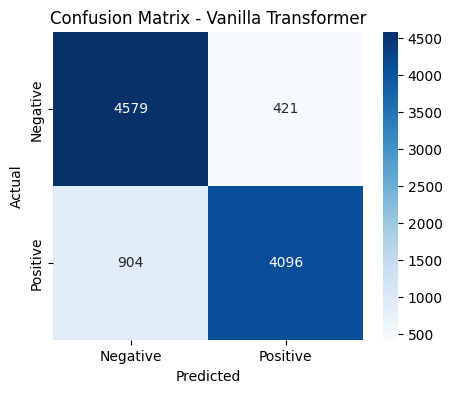

In [6]:
# Build custom Transformer Encoder block layer in Keras
class TransformerEncoderBlock(tf.keras.layers.Layer):
    def __init__(self, embed_dim, num_heads, ff_dim, rate=0.1):
        super(TransformerEncoderBlock, self).__init__()
        self.att = MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim)
        self.ffn = Sequential([
            Dense(ff_dim, activation="relu"),
            Dense(embed_dim),
        ])
        self.layernorm1 = LayerNormalization(epsilon=1e-6)
        self.layernorm2 = LayerNormalization(epsilon=1e-6)
        self.dropout1 = Dropout(rate)
        self.dropout2 = Dropout(rate)

    def call(self, inputs, training=None):
        attn_output = self.att(inputs, inputs)
        attn_output = self.dropout1(attn_output, training=training)
        out1 = self.layernorm1(inputs + attn_output)
        ffn_output = self.ffn(out1)
        ffn_output = self.dropout2(ffn_output, training=training)
        return self.layernorm2(out1 + ffn_output)

# Simple positional embedding layer
class TokenAndPositionEmbedding(tf.keras.layers.Layer):
    def __init__(self, maxlen, vocab_size, embed_dim):
        super(TokenAndPositionEmbedding, self).__init__()
        self.token_emb = Embedding(input_dim=vocab_size, output_dim=embed_dim)
        self.pos_emb = Embedding(input_dim=maxlen, output_dim=embed_dim)

    def call(self, x):
        maxlen = tf.shape(x)[-1]
        positions = tf.range(start=0, limit=maxlen, delta=1)
        positions = self.pos_emb(positions)
        x = self.token_emb(x)
        return x + positions

embed_dim = 32  # Embedding size for each token
num_heads = 2   # Number of attention heads
ff_dim = 32     # Hidden layer size in feed forward network inside transformer

inputs = tf.keras.Input(shape=(max_len,))
embedding_layer = TokenAndPositionEmbedding(max_len, max_words, embed_dim)(inputs)
x = TransformerEncoderBlock(embed_dim, num_heads, ff_dim)(embedding_layer)
x = GlobalAveragePooling1D()(x)
x = Dropout(0.1)(x)
x = Dense(20, activation="relu")(x)
x = Dropout(0.1)(x)
outputs = Dense(1, activation="sigmoid")(x)

transformer_model = tf.keras.Model(inputs=inputs, outputs=outputs)
transformer_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
transformer_model.summary()

# Train Transformer
history_transformer = transformer_model.fit(
    X_train_seq, y_train,
    batch_size=128,
    epochs=3,
    validation_split=0.1
)

# Predict and Evaluate
transformer_probs = transformer_model.predict(X_test_seq)
transformer_preds = (transformer_probs > 0.5).astype(int).flatten()
evaluate_model(y_test, transformer_preds, "Vanilla Transformer")

## Model 4: Pre-trained BERT (Using HuggingFace Transformers)

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(load

Epoch,Training Loss,Validation Loss
1,No log,0.425970


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


--- BERT (DistilBERT) Performance ---
              precision    recall  f1-score   support

    Negative       0.90      0.78      0.83       251
    Positive       0.80      0.91      0.85       249

    accuracy                           0.84       500
   macro avg       0.85      0.84      0.84       500
weighted avg       0.85      0.84      0.84       500



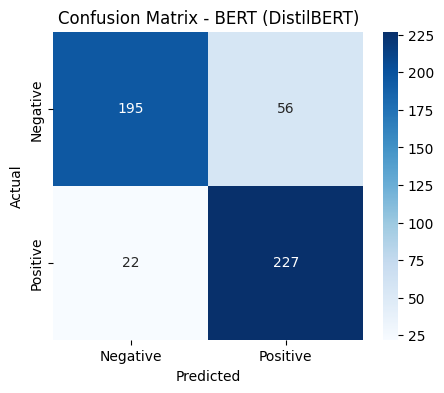

In [8]:
# Install transformers
!pip install -q transformers datasets accelerate

import torch
import numpy as np
import pandas as pd
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset

# Load pre-trained BERT tokenizer (using a small, fast model distilbert)
model_name = "distilbert-base-uncased"
transformer_tokenizer = AutoTokenizer.from_pretrained(model_name)

# Prepare dataset splits compatible with HF Trainer (using a small subset to fit into runtime resource limits)
train_df_subset = pd.DataFrame({'text': X_train_raw, 'label': y_train}).sample(1500, random_state=42)
test_df_subset = pd.DataFrame({'text': X_test_raw, 'label': y_test}).sample(500, random_state=42)

train_ds = Dataset.from_pandas(train_df_subset)
test_ds = Dataset.from_pandas(test_df_subset)

def tokenize_function(examples):
    return transformer_tokenizer(examples["text"], padding="max_length", truncation=True, max_length=128)

tokenized_train = train_ds.map(tokenize_function, batched=True)
tokenized_test = test_ds.map(tokenize_function, batched=True)

# Load pretrained sequence classification model
bert_model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)

# Define Trainer Arguments (Updated evaluation_strategy to eval_strategy to match newer transformers APIs)
training_args = TrainingArguments(
    output_dir="./results",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=1,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    report_to="none"
)

trainer = Trainer(
    model=bert_model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test
)

# Train BERT
trainer.train()

# Predict
bert_predictions = trainer.predict(tokenized_test)
bert_preds = np.argmax(bert_predictions.predictions, axis=1)
y_test_subset = test_df_subset['label'].values

# Evaluate on the evaluation subset
evaluate_model(y_test_subset, bert_preds, "BERT (DistilBERT)")

## Comparative Analysis

,Accuracy,Precision,Recall,F1-Score
Logistic Regression,0.8972,0.8922,0.9036,0.8979
LSTM,0.6218,0.5844,0.8430,0.6903
Vanilla Transformer,0.8675,0.9068,0.8192,0.8608
BERT (DistilBERT),0.8440,0.8021,0.9116,0.8534


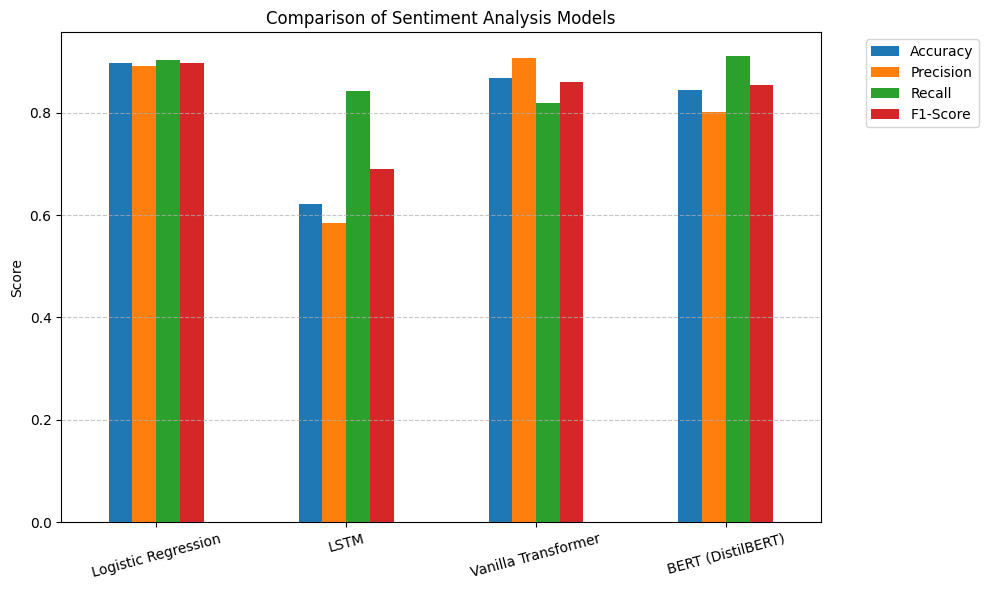

In [9]:
# Build performance comparison DataFrame
comparison_df = pd.DataFrame(metrics_dict).T
display(comparison_df.round(4))

# Plot Comparative Metrics
comparison_df[['Accuracy', 'Precision', 'Recall', 'F1-Score']].plot(kind='bar', figsize=(10, 6))
plt.title('Comparison of Sentiment Analysis Models')
plt.ylabel('Score')
plt.xticks(rotation=15)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()